# Expected stat curve

Load one policy result zarr, select one statistic and one or two x dimensions, average over the other dimensions, then plot.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

project_root = Path.cwd()
if not (project_root / "tasks").exists():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

try:
    import scienceplots  # noqa: F401
except ModuleNotFoundError:
    pass
else:
    plt.style.use("science")

from tasks.policies import load_policy_results

In [2]:
def marginal_stat_curve(ds, stat, dimensions, filters):
    selected_dimensions = tuple(dimensions)
    if len(selected_dimensions) not in {1, 2}:
        raise ValueError("Set dimensions to one or two names.")

    y = ds["x"].sel(observable=stat).isel(step=-1, drop=True)
    dimension_filters = {name: value for name, value in filters.items() if name in y.dims}
    theta_filters = {name: value for name, value in filters.items() if name not in y.dims}

    if dimension_filters:
        y = y.sel(dimension_filters)

    for name, value in theta_filters.items():
        theta_value = ds["theta"].sel(theta_parameter=name, drop=True)
        if dimension_filters:
            theta_value = theta_value.sel(dimension_filters)
        theta_value, y = xr.align(theta_value, y, join="exact")
        try:
            y = y.where(np.isclose(theta_value, value))
        except TypeError:
            y = y.where(theta_value == value)

    plot_ds = xr.Dataset({"value": y})
    for name in selected_dimensions:
        if name in y.dims:
            continue
        coord = ds["theta"].sel(theta_parameter=name, drop=True)
        if dimension_filters:
            coord_filters = {
                dim: value
                for dim, value in dimension_filters.items()
                if dim in coord.dims
            }
            coord = coord.sel(coord_filters)
        coord, y = xr.align(coord, y, join="exact")
        plot_ds = plot_ds.assign_coords({name: coord})

    frame = plot_ds.to_dataframe().reset_index()
    frame = frame.dropna(subset=["value", *selected_dimensions])
    curve = (
        frame.groupby(list(selected_dimensions), as_index=False, dropna=True)["value"]
        .mean()
        .rename(columns={"value": "mean"})
        .sort_values(list(selected_dimensions))
    )
    return curve, selected_dimensions

In [3]:
result_store = "artifacts/simulation_runs/run-20260514T024051.zarr"

In [4]:
result_store_path = Path(result_store).expanduser()
if not result_store_path.is_absolute():
    result_store_path = project_root / result_store_path

ds = load_policy_results(result_store_path)

print(f"Loaded: {result_store_path.relative_to(project_root)}")
print("Stats:", list(ds.coords["observable"].values))
print("xarray dimensions:", list(ds["x"].dims))
print("theta parameters:", list(ds.coords["theta_parameter"].values))

Loaded: artifacts/simulation_runs/run-20260514T024051.zarr
Stats: [np.str_('central_point_of_dominance.mean'), np.str_('indegree.mean'), np.str_('centered_mean_welfare.mean')]
xarray dimensions: ['n_agents', 'best_response_proportion', 'parameter_row', 'step', 'observable']
theta parameters: [np.str_('n_agents'), np.str_('benefit_to_cost_ratio'), np.str_('distance_discount'), np.str_('visibility_distance'), np.str_('best_response.outside_optimism'), np.str_('best_response.exploration'), np.str_('random.p_act')]


In [5]:
stat = "centered_mean_welfare.mean"
dimensions = ("best_response_proportion", "random.p_act")

/tmp/ipykernel_39475/3208271363.py:203: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


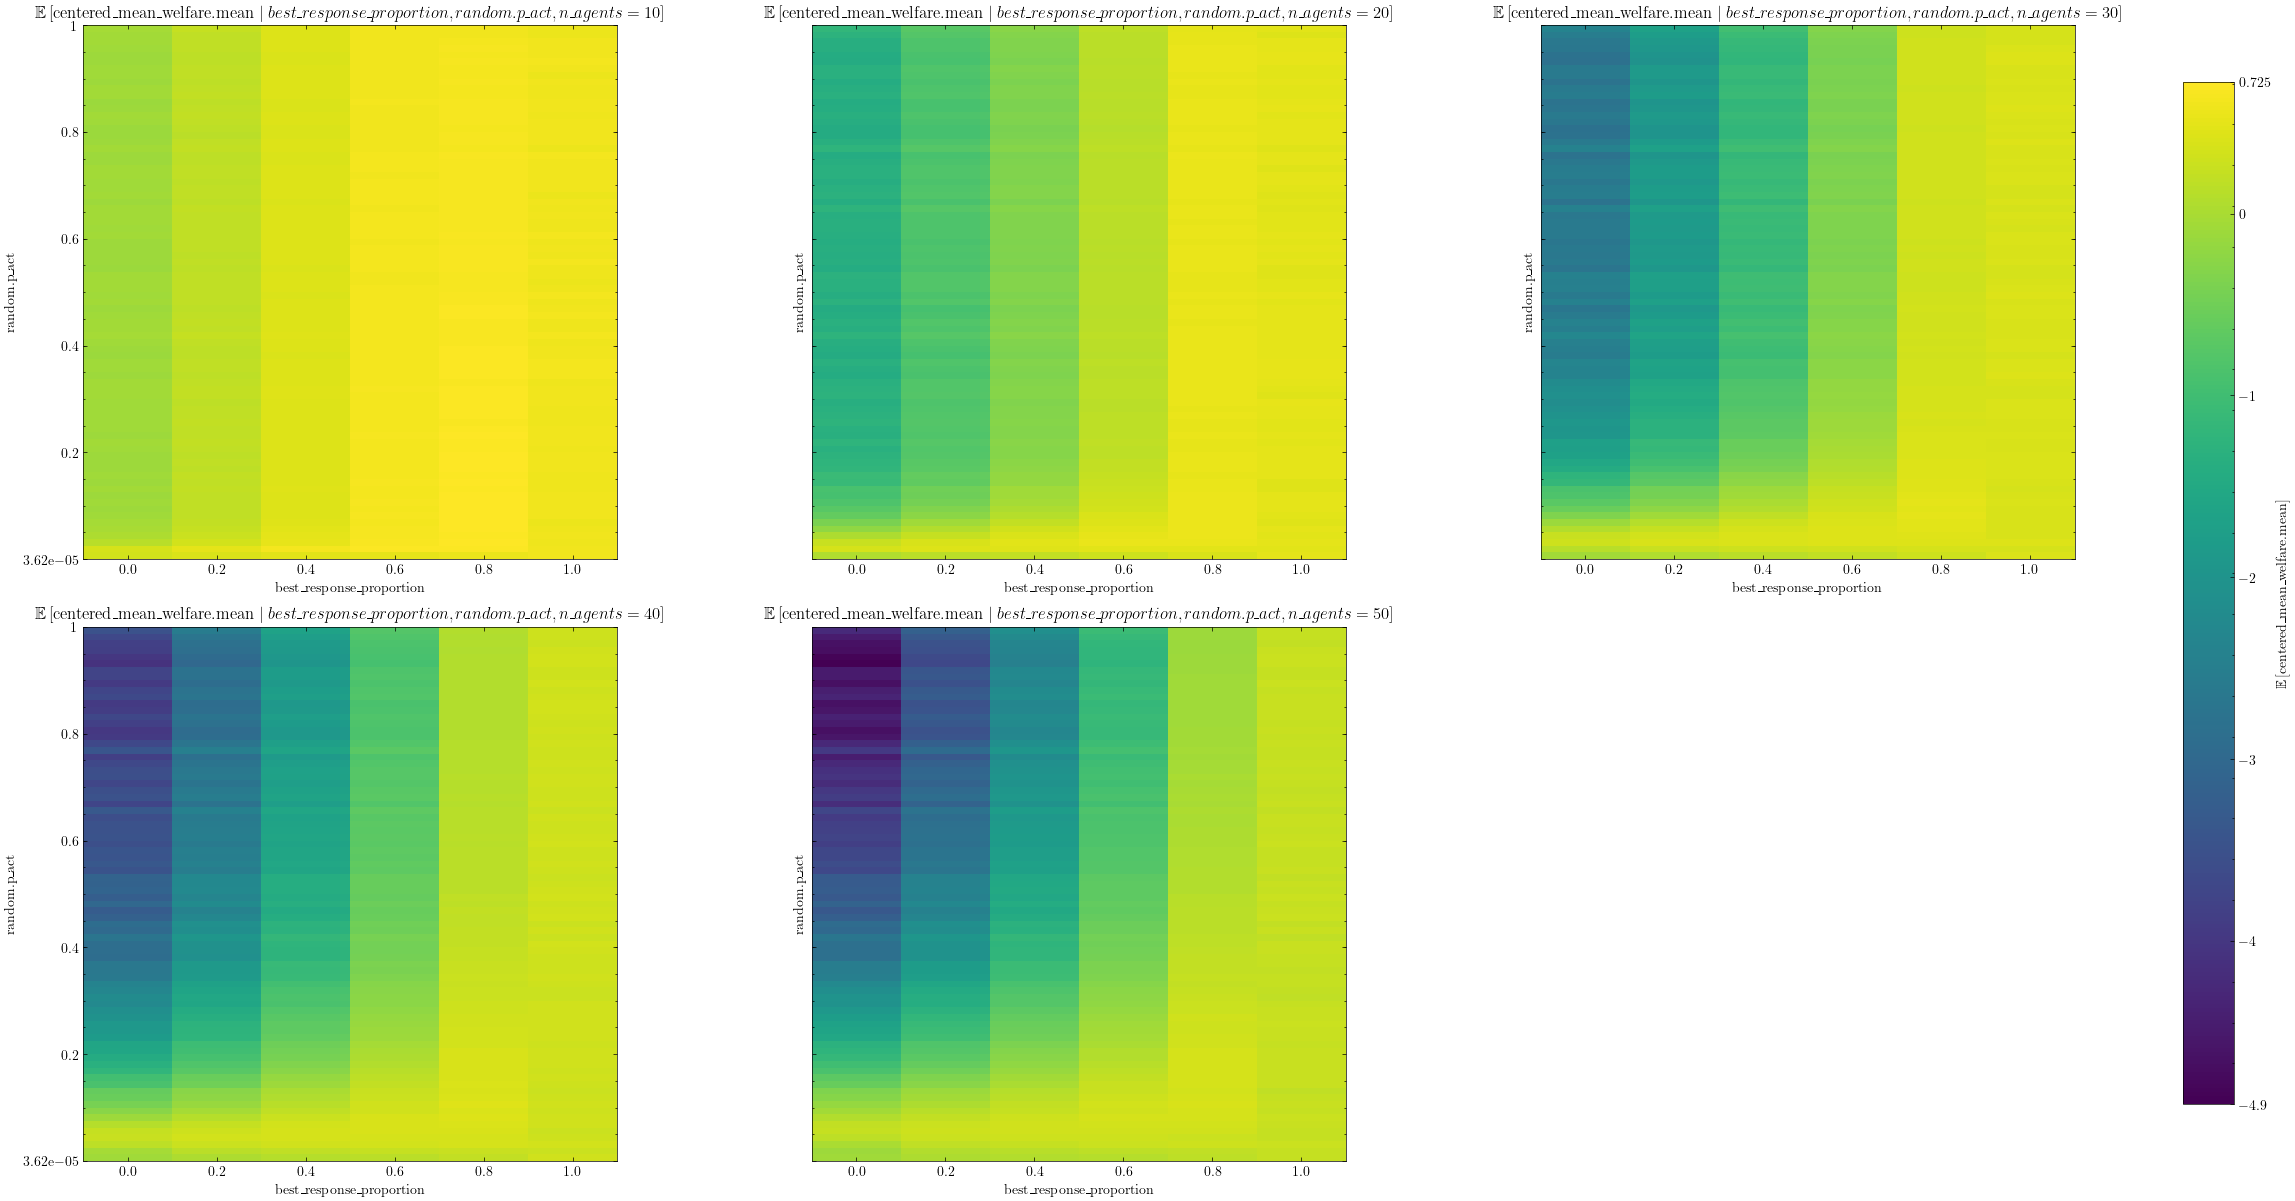

In [7]:
filters = dict()

n_agents_options = ds.n_agents.values

ncols = 3
nrows = (len(n_agents_options) + ncols - 1) // ncols

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(8 * ncols, 6 * nrows),
    sharey=True,
    constrained_layout=True
)
axes = axes.flatten()

heatmap_bins = 80


def discrete_edges(values):
    values = np.asarray(values, dtype=float)
    values = np.sort(np.unique(values[np.isfinite(values)]))
    if len(values) == 0:
        return np.array([0.0, 1.0])
    if len(values) == 1:
        return np.array([values[0] - 0.5, values[0] + 0.5])

    midpoints = (values[:-1] + values[1:]) / 2
    first_edge = values[0] - (midpoints[0] - values[0])
    last_edge = values[-1] + (values[-1] - midpoints[-1])
    return np.concatenate([[first_edge], midpoints, [last_edge]])


def binned_edges(values, bins):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if len(values) == 0:
        return np.linspace(0.0, 1.0, bins + 1)

    lower = float(values.min())
    upper = float(values.max())
    if lower == upper:
        return np.array([lower - 0.5, upper + 0.5])
    return np.linspace(lower, upper, bins + 1)


def endpoint_ticks(existing_ticks, lower, upper):
    existing_ticks = np.asarray(existing_ticks, dtype=float)
    inner_ticks = existing_ticks[
        np.isfinite(existing_ticks)
        & (existing_ticks > lower)
        & (existing_ticks < upper)
    ]
    return np.unique(np.concatenate([[lower], inner_ticks, [upper]]))


def binned_heatmap(curve, x_dim, y_dim, x_values, y_edges):
    heatmap = np.full((len(y_edges) - 1, len(x_values)), np.nan)
    x = curve[x_dim].to_numpy(dtype=float)
    y = curve[y_dim].to_numpy(dtype=float)

    x_bins = np.searchsorted(x_values, x)
    y_bins = np.searchsorted(y_edges, y, side="right") - 1
    y_bins[y == y_edges[-1]] = len(y_edges) - 2

    valid = (
        np.isfinite(x)
        & np.isfinite(y)
        & (x_bins >= 0)
        & (x_bins < len(x_values))
        & np.isclose(x_values[np.clip(x_bins, 0, len(x_values) - 1)], x)
        & (y_bins >= 0)
        & (y_bins < len(y_edges) - 1)
    )

    cell_means = (
        curve.loc[valid]
        .assign(x_bin=x_bins[valid], y_bin=y_bins[valid])
        .groupby(["y_bin", "x_bin"], dropna=True)["mean"]
        .mean()
    )
    for (y_bin, x_bin), value in cell_means.items():
        heatmap[int(y_bin), int(x_bin)] = value
    return heatmap


plot_data = []
color_values = []

for n_agents in n_agents_options:
    subplot_filters = {**filters, "n_agents": n_agents}
    curve, selected_dimensions = marginal_stat_curve(ds, stat, dimensions, subplot_filters)
    plot_data.append((subplot_filters, curve, selected_dimensions))

heatmap_grids = [None] * len(plot_data)
two_dim_indices = [
    index
    for index, (_, _, selected_dimensions) in enumerate(plot_data)
    if len(selected_dimensions) > 1
]

if two_dim_indices:
    _, _, selected_dimensions = plot_data[two_dim_indices[0]]
    x_dim, y_dim = selected_dimensions
    x_values = np.sort(
        np.unique(
            np.concatenate([
                plot_data[index][1][x_dim].to_numpy(dtype=float)
                for index in two_dim_indices
            ])
        )
    )
    x_values = x_values[np.isfinite(x_values)]
    if len(x_values) == 0:
        x_values = np.array([0.0])
    y_values = np.concatenate([
        plot_data[index][1][y_dim].to_numpy(dtype=float)
        for index in two_dim_indices
    ])
    x_edges = discrete_edges(x_values)
    y_edges = binned_edges(y_values, heatmap_bins)

    for index in two_dim_indices:
        _, curve, selected_dimensions = plot_data[index]
        x_dim, y_dim = selected_dimensions
        heatmap = binned_heatmap(curve, x_dim, y_dim, x_values, y_edges)
        heatmap_grids[index] = heatmap
        finite_values = heatmap[np.isfinite(heatmap)]
        if len(finite_values):
            color_values.append(finite_values)
else:
    x_edges = y_edges = None

if color_values:
    vmin = min(float(values.min()) for values in color_values)
    vmax = max(float(values.max()) for values in color_values)
    if vmin == vmax:
        vmin -= 0.5
        vmax += 0.5
else:
    vmin = vmax = None

mappable = None
colorbar_label = None

for i, (subplot_filters, curve, selected_dimensions) in enumerate(plot_data):
    stat_title = stat.replace("_", r"\_")
    dimension_title = [name.replace("_", r"\_") for name in selected_dimensions]
    filter_title = [
        f"{name.replace('_', r'\_')}={value}"
        for name, value in subplot_filters.items()
    ]

    condition_title = ", ".join([*dimension_title, *filter_title])
    mean_label = rf"$\mathbb{{E}}\left[\mathrm{{{stat_title}}} \mid {condition_title}\right]$"

    if len(selected_dimensions) == 1:
        x_dim = selected_dimensions[0]
        axes[i].plot(curve[x_dim], curve["mean"], marker="o", linewidth=1.5)
        axes[i].set_xlabel(x_dim)
        axes[i].set_ylabel(mean_label)
        axes[i].grid(alpha=0.25)
    else:
        x_dim, y_dim = selected_dimensions
        mesh = axes[i].pcolormesh(
            x_edges,
            y_edges,
            np.ma.masked_invalid(heatmap_grids[i]),
            cmap="viridis",
            vmin=vmin,
            vmax=vmax,
            shading="flat"
        )
        mappable = mesh
        colorbar_label = rf"$\mathbb{{E}}\left[\mathrm{{{stat_title}}}\right]$"
        axes[i].set_xlabel(x_dim)
        axes[i].set_ylabel(y_dim)
        axes[i].set_xlim(x_edges[0], x_edges[-1])
        axes[i].set_ylim(y_edges[0], y_edges[-1])
        axes[i].set_xticks(x_values)
        axes[i].set_xticks([], minor=True)
        axes[i].set_yticks(endpoint_ticks(axes[i].get_yticks(), y_edges[0], y_edges[-1]))
        axes[i].yaxis.set_major_formatter("{x:.3g}")
        axes[i].grid(False)

    axes[i].set_title(mean_label)
    axes[i].set_box_aspect(1)

for j in range(len(plot_data), len(axes)):
    axes[j].set_visible(False)

if mappable is not None:
    colorbar = fig.colorbar(
        mappable,
        ax=axes[:len(plot_data)],
        label=colorbar_label,
        shrink=0.9
    )
    if vmin is not None and vmax is not None:
        colorbar.set_ticks(endpoint_ticks(colorbar.get_ticks(), vmin, vmax))
        colorbar.ax.yaxis.set_major_formatter("{x:.3g}")

fig.show()